# Robustness of a pretrained audio watermark detector under realistic processing

**Question:** How does the performance of a pretrained audio-watermark detector (AudioSeal) change after compression, resampling, band-limiting, noise and mixing with other speech?

**Design in one paragraph:** take clean read-speech clips, embed a 16-bit watermark in half of the experiment, then apply the *same* processing to both the watermarked clips and their unwatermarked originals. For every processing condition, report detection rate, false-positive rate, AUC with a bootstrap confidence interval, true-positive rate at 1% false-positive rate, and watermark-message bit accuracy. Testing clean clips under every attack matters: a detector that fires on everything would otherwise look robust.

**How to run (Google Colab):** Runtime → Change runtime type → GPU (optional, CPU also works). Then Runtime → Run all. Expect roughly 10–30 minutes. Results are saved in `results/`.

In [1]:
!pip -q install audioseal soundfile scikit-learn pandas matplotlib tabulate scipy
!ffmpeg -version | head -1

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers


## 1. Configuration and environment record

In [2]:
import os, json, random, subprocess, tempfile, platform
import importlib.metadata as md
import numpy as np, pandas as pd, soundfile as sf
import scipy.signal as sps
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

SEED     = 42
N_CLIPS  = 60        # clips per class (watermarked / clean). Raise to 100+ if time allows.
SR       = 16000     # AudioSeal operates at 16 kHz
MIN_SEC, MAX_SEC = 3, 8
OUT = "results"; os.makedirs(OUT, exist_ok=True)

random.seed(SEED); np.random.seed(SEED)

def ver(pkg):
    try: return md.version(pkg)
    except Exception: return "n/a"

ENV = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "seed": SEED, "n_clips_per_class": N_CLIPS,
    **{p: ver(p) for p in ["audioseal","torch","torchaudio","numpy","scipy","scikit-learn","soundfile"]},
    "ffmpeg": subprocess.run(["ffmpeg","-version"],capture_output=True,text=True).stdout.splitlines()[0],
}
print(json.dumps(ENV, indent=2))

{
  "python": "3.13.16",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "seed": 42,
  "n_clips_per_class": 60,
  "audioseal": "0.2.0",
  "torch": "2.11.0+cpu",
  "torchaudio": "2.11.0+cpu",
  "numpy": "2.1.3",
  "scipy": "1.16.3",
  "scikit-learn": "1.6.1",
  "soundfile": "0.14.0",
  "ffmpeg": "ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers"
}


## 2. Data
LibriSpeech `dev-clean` (clean read English speech). Clips are 3–8 s, mono, 16 kHz. A second, disjoint set of utterances is used as the *interfering speech* for the mixing attack.

In [3]:
import torch, torchaudio
os.makedirs("data", exist_ok=True)   # torchaudio does not create the download folder itself
ds = torchaudio.datasets.LIBRISPEECH("data", url="dev-clean", download=True)

order = list(range(len(ds))); random.Random(SEED).shuffle(order)
pool, ids = [], []
for i in order:
    wav, sr, _, spk, chap, utt = ds[i]
    assert sr == SR
    if wav.shape[1] < MIN_SEC * SR:
        continue
    pool.append(wav.squeeze(0).numpy()[: MAX_SEC * SR].astype(np.float32))
    ids.append(f"{spk}-{chap}-{utt}")
    if len(pool) == 2 * N_CLIPS:
        break

clean = pool[:N_CLIPS]            # target clips
intf  = pool[N_CLIPS:]            # interfering speech for the mixing attack
clip_ids = ids[:N_CLIPS]
print(len(clean), "target clips;", len(intf), "interferer clips")

100%|██████████| 322M/322M [00:28<00:00, 12.0MB/s]


60 target clips; 60 interferer clips


## 3. Watermark embedding with AudioSeal
Each clip gets a random 16-bit message (seeded), so we can measure message recovery as well as detection. If your installed `audioseal` version names things differently, check the project README for `load_generator`, `get_watermark` and `detect_watermark`.

In [4]:
from audioseal import AudioSeal
device = "cuda" if torch.cuda.is_available() else "cpu"
generator = AudioSeal.load_generator("audioseal_wm_16bits").to(device).eval()
detector  = AudioSeal.load_detector("audioseal_detector_16bits").to(device).eval()

msgs = np.random.default_rng(SEED).integers(0, 2, size=(N_CLIPS, 16))

@torch.no_grad()
def embed(x, msg):
    t = torch.from_numpy(x).view(1, 1, -1).to(device)
    m = torch.from_numpy(msg).view(1, -1).long().to(device)
    wm = generator.get_watermark(t, SR, message=m)
    return (t + wm).clamp(-1, 1).view(-1).cpu().numpy().astype(np.float32)

@torch.no_grad()
def detect(x):
    t = torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)).view(1, 1, -1).to(device)
    prob, bits = detector.detect_watermark(t, SR)
    prob = float(torch.as_tensor(prob).flatten()[0])
    bits = torch.as_tensor(bits).flatten()[:16].float().cpu().numpy()
    return prob, bits

wm = [embed(clean[i], msgs[i]) for i in range(N_CLIPS)]

# Sanity checks before the long run
p_wm, _ = detect(wm[0]); p_cl, _ = detect(clean[0])
print(f"smoke test  watermarked score={p_wm:.3f}   clean score={p_cl:.3f}")
snr = [10*np.log10((c**2).mean() / (((w - c)**2).mean() + 1e-12)) for c, w in zip(clean, wm)]
print(f"watermark-to-signal level (SNR of original vs. embedded change): mean {np.mean(snr):.1f} dB")
if not (p_wm > 0.5 > p_cl):
    print("WARNING: smoke test failed. Check API usage before trusting any results below.")

Downloading: "https://huggingface.co/facebook/audioseal/resolve/main/generator_base.pth" to /root/.cache/audioseal/0f195d476dd87ca1bd7b09e6


100%|██████████| 56.1M/56.1M [00:00<00:00, 124MB/s]
/usr/local/lib/python3.13/dist-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Downloading: "https://huggingface.co/facebook/audioseal/resolve/main/detector_base.pth" to /root/.cache/audioseal/94c8df0b1d5ea8e45af4c884


100%|██████████| 33.1M/33.1M [00:00<00:00, 68.0MB/s]
W1024 21:51:48.736000 1916 torch/_dynamo/convert_frame.py:1743] [1/8] torch._dynamo hit config.recompile_limit (8)
W1024 21:51:48.736000 1916 torch/_dynamo/convert_frame.py:1743] [1/8]    function: 'forward' (/usr/local/lib/python3.13/dist-packages/audioseal/libs/moshi/modules/conv.py:248)
W1024 21:51:48.736000 1916 torch/_dynamo/convert_frame.py:1743] [1/8]    last reason: 1/7: tensor 'x' size mismatch at index 1. expected 32, actual 1
W1024 21:51:48.736000 1916 torch/_dynamo/convert_frame.py:1743] [1/8] To log all recompilation reasons, use TORCH_LOGS="recompiles".
W1024 21:51:48.736000 1916 torch/_dynamo/convert_frame.py:1743] [1/8] To diagnose recompilation issues, see https://docs.pytorch.org/docs/main/user_guide/torch_compiler/compile/programming_model.recompilation.html
W1024 21:51:48.768000 1916 torch/_dynamo/convert_frame.py:1743] [2/8] torch._dynamo hit config.recompile_limit (8)
W1024 21:51:48.768000 1916 torch/_dynamo/con

smoke test  watermarked score=1.000   clean score=0.002
watermark-to-signal level (SNR of original vs. embedded change): mean 26.5 dB


## 4. Processing conditions ("attacks")
All conditions are applied identically to watermarked clips and clean clips. They are simple, non-adaptive transformations — *not* an adversary who knows the detector.

In [5]:
def fit(y, T):
    return np.pad(y, (0, max(0, T - len(y))))[:T].astype(np.float32)

def mp3(x, kbps, seed=0):
    with tempfile.TemporaryDirectory() as d:
        a, m, o = f"{d}/in.wav", f"{d}/o.mp3", f"{d}/o.wav"
        sf.write(a, x, SR)
        subprocess.run(["ffmpeg","-y","-loglevel","error","-i",a,"-codec:a","libmp3lame","-b:a",f"{kbps}k",m], check=True)
        subprocess.run(["ffmpeg","-y","-loglevel","error","-i",m,"-ar",str(SR),"-ac","1",o], check=True)
        y, _ = sf.read(o, dtype="float32")
    return fit(y, len(x))

def resample_8k(x, seed=0):
    y = sps.resample_poly(sps.resample_poly(x, 1, 2), 2, 1)
    return fit(y.astype(np.float32), len(x))

def lowpass(x, hz=4000, seed=0):
    sos = sps.butter(4, hz, btype="low", fs=SR, output="sos")
    return sps.sosfilt(sos, x).astype(np.float32)

def add_at_snr(x, n, snr_db):
    n = np.resize(n, len(x)).astype(np.float32)
    scale = np.sqrt((x**2).mean() / (((n**2).mean() + 1e-12) * 10**(snr_db / 10)))
    return np.clip(x + scale * n, -1, 1).astype(np.float32)

def gauss(x, snr_db, seed=0):
    n = np.random.default_rng(seed).standard_normal(len(x))
    return add_at_snr(x, n, snr_db)

def babble(x, other, snr_db):
    return add_at_snr(x, other, snr_db)

# every attack has the signature f(x, interferer, seed)
ATTACKS = {
    "none":          lambda x, o, s: x,
    "mp3_128k":      lambda x, o, s: mp3(x, 128),
    "mp3_64k":       lambda x, o, s: mp3(x, 64),
    "mp3_32k":       lambda x, o, s: mp3(x, 32),
    "resample_8k":   lambda x, o, s: resample_8k(x),
    "lowpass_4k":    lambda x, o, s: lowpass(x, 4000),
    "noise_20dB":    lambda x, o, s: gauss(x, 20, s),
    "noise_10dB":    lambda x, o, s: gauss(x, 10, s),
    "noise_0dB":     lambda x, o, s: gauss(x, 0, s),
    "speech_mix_10dB": lambda x, o, s: babble(x, o, 10),
    "speech_mix_5dB":  lambda x, o, s: babble(x, o, 5),
    "speech_mix_0dB":  lambda x, o, s: babble(x, o, 0),
}
print(list(ATTACKS))

['none', 'mp3_128k', 'mp3_64k', 'mp3_32k', 'resample_8k', 'lowpass_4k', 'noise_20dB', 'noise_10dB', 'noise_0dB', 'speech_mix_10dB', 'speech_mix_5dB', 'speech_mix_0dB']


## 5. Evaluation
Per condition: detection scores for watermarked clips (positives) and clean clips (negatives), threshold 0.5 (AudioSeal's default), AUC with a 95% bootstrap interval over clips, TPR at ≤1% FPR, and mean message bit accuracy on the watermarked clips.

In [6]:
def tpr_at_fpr(y, s, target=0.01):
    fpr, tpr, _ = roc_curve(y, s)
    ok = fpr <= target
    return float(tpr[ok].max()) if ok.any() else 0.0

def boot_auc(pos, neg, B=500, seed=0):
    rng = np.random.default_rng(seed); n = len(pos); vals = []
    for _ in range(B):
        p = pos[rng.integers(0, n, n)]; q = neg[rng.integers(0, n, n)]
        vals.append(roc_auc_score(np.r_[np.ones(n), np.zeros(n)], np.r_[p, q]))
    return np.percentile(vals, [2.5, 97.5])

def run_eval(wm, clean, intf, msgs, detect_fn, attacks, thr=0.5, seed=SEED):
    rows, clips = [], []
    for name, fn in attacks.items():
        pos, neg, bacc = [], [], []
        for i in range(len(wm)):
            p, bits = detect_fn(fn(wm[i], intf[i], seed + i))
            q, _    = detect_fn(fn(clean[i], intf[i], seed + i))
            pos.append(p); neg.append(q)
            bacc.append(float((np.round(bits).astype(int) == msgs[i]).mean()))
            clips.append(dict(attack=name, clip=i, score_watermarked=p, score_clean=q, bit_acc=bacc[-1]))
        pos, neg = np.array(pos), np.array(neg)
        y = np.r_[np.ones(len(pos)), np.zeros(len(neg))]; s = np.r_[pos, neg]
        lo, hi = boot_auc(pos, neg, seed=seed)
        rows.append(dict(
            attack=name,
            TPR_at_0_5=float((pos > thr).mean()), FPR_at_0_5=float((neg > thr).mean()),
            AUC=roc_auc_score(y, s), AUC_lo=lo, AUC_hi=hi,
            TPR_at_1pct_FPR=tpr_at_fpr(y, s),
            bit_acc=float(np.mean(bacc)),
            mean_score_wm=float(pos.mean()), mean_score_clean=float(neg.mean()),
        ))
        print(f"{name:16s} AUC={rows[-1]['AUC']:.3f}  TPR@.5={rows[-1]['TPR_at_0_5']:.2f}  FPR@.5={rows[-1]['FPR_at_0_5']:.2f}  bitacc={rows[-1]['bit_acc']:.2f}")
    return pd.DataFrame(rows), pd.DataFrame(clips)

In [7]:
results, per_clip = run_eval(wm, clean, intf, msgs, detect, ATTACKS)
results.round(3)

none             AUC=1.000  TPR@.5=1.00  FPR@.5=0.00  bitacc=1.00
mp3_128k         AUC=1.000  TPR@.5=1.00  FPR@.5=0.00  bitacc=1.00
mp3_64k          AUC=1.000  TPR@.5=1.00  FPR@.5=0.00  bitacc=1.00
mp3_32k          AUC=1.000  TPR@.5=1.00  FPR@.5=0.00  bitacc=1.00
resample_8k      AUC=1.000  TPR@.5=1.00  FPR@.5=0.00  bitacc=1.00
lowpass_4k       AUC=1.000  TPR@.5=1.00  FPR@.5=0.00  bitacc=0.92
noise_20dB       AUC=1.000  TPR@.5=0.35  FPR@.5=0.00  bitacc=0.96
noise_10dB       AUC=1.000  TPR@.5=0.00  FPR@.5=0.00  bitacc=0.79
noise_0dB        AUC=0.889  TPR@.5=0.00  FPR@.5=0.00  bitacc=0.56
speech_mix_10dB  AUC=1.000  TPR@.5=0.97  FPR@.5=0.00  bitacc=1.00
speech_mix_5dB   AUC=1.000  TPR@.5=0.83  FPR@.5=0.00  bitacc=0.99
speech_mix_0dB   AUC=1.000  TPR@.5=0.68  FPR@.5=0.00  bitacc=0.98


,attack,TPR_at_0_5,FPR_at_0_5,AUC,AUC_lo,AUC_hi,TPR_at_1pct_FPR,bit_acc,mean_score_wm,mean_score_clean
0,none,1.000,0.0,1.000,1.00,1.000,1.000,1.000,1.000,0.001
1,mp3_128k,1.000,0.0,1.000,1.00,1.000,1.000,1.000,1.000,0.001
2,mp3_64k,1.000,0.0,1.000,1.00,1.000,1.000,1.000,1.000,0.001
3,mp3_32k,1.000,0.0,1.000,1.00,1.000,1.000,1.000,0.999,0.001
4,resample_8k,1.000,0.0,1.000,1.00,1.000,1.000,1.000,1.000,0.001
5,lowpass_4k,1.000,0.0,1.000,1.00,1.000,1.000,0.921,1.000,0.001
6,noise_20dB,0.350,0.0,1.000,1.00,1.000,1.000,0.956,0.504,0.000
7,noise_10dB,0.000,0.0,1.000,1.00,1.000,1.000,0.786,0.225,0.001
8,noise_0dB,0.000,0.0,0.889,0.83,0.938,0.517,0.559,0.037,0.001
9,speech_mix_10dB,0.967,0.0,1.000,1.00,1.000,1.000,0.998,0.807,0.001


## 6. Save results, figure and write-up

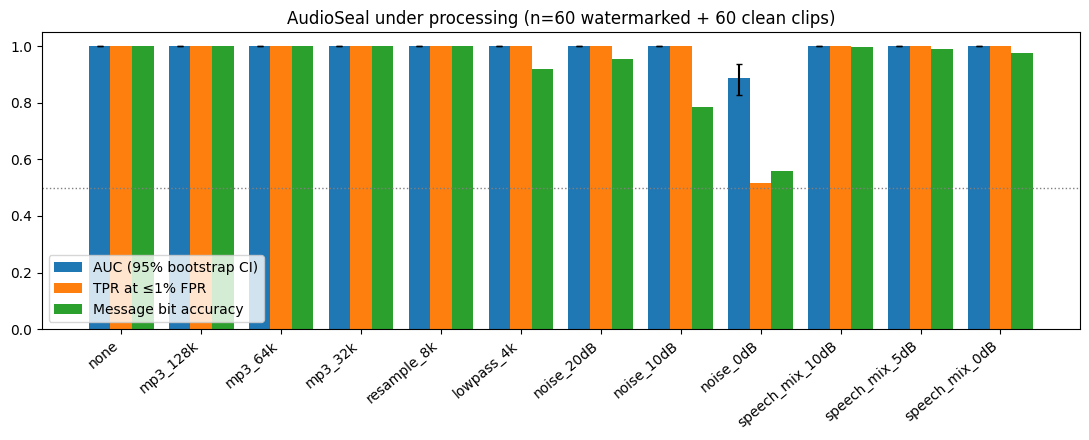

In [8]:
results.round(4).to_csv(f"{OUT}/results_by_attack.csv", index=False)
per_clip.round(5).to_csv(f"{OUT}/per_clip_scores.csv", index=False)
json.dump(ENV, open(f"{OUT}/environment.json", "w"), indent=2)

fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(results)); w = 0.27
ax.bar(x - w, results["AUC"], w, label="AUC (95% bootstrap CI)",
       yerr=[results["AUC"] - results["AUC_lo"], results["AUC_hi"] - results["AUC"]], capsize=2)
ax.bar(x,     results["TPR_at_1pct_FPR"], w, label="TPR at ≤1% FPR")
ax.bar(x + w, results["bit_acc"], w, label="Message bit accuracy")
ax.axhline(0.5, ls=":", c="grey", lw=1)
ax.set_xticks(x); ax.set_xticklabels(results["attack"], rotation=40, ha="right")
ax.set_ylim(0, 1.05); ax.set_title(f"AudioSeal under processing (n={N_CLIPS} watermarked + {N_CLIPS} clean clips)")
ax.legend(loc="lower left"); plt.tight_layout()
plt.savefig(f"{OUT}/robustness.png", dpi=200); plt.show()

In [9]:
table = results[["attack","AUC","AUC_lo","AUC_hi","TPR_at_0_5","FPR_at_0_5","TPR_at_1pct_FPR","bit_acc"]].round(3).to_markdown(index=False)
readme = f'''# Robustness of a pretrained audio watermark detector under realistic processing

Small, exploratory evaluation of AudioSeal (16-bit pretrained generator/detector) on LibriSpeech dev-clean.

**Setup.** {N_CLIPS} clips (3–8 s, 16 kHz) are watermarked with random 16-bit messages. Each processing condition is applied
identically to the watermarked clips and to the {N_CLIPS} unwatermarked originals. Detection threshold 0.5 (AudioSeal default).
Seed {SEED}. Package versions are in `environment.json`; per-clip scores are in `per_clip_scores.csv`.

## Results

{table}

AUC intervals are 95% bootstrap intervals over clips. Message bit accuracy is measured on watermarked clips only.

![results](robustness.png)

## Limitations
- Small sample ({N_CLIPS} clips per class); TPR at 1% FPR has coarse resolution with this many negatives.
- One watermarking method (pretrained AudioSeal), one dataset (clean read English speech), one run per condition.
- Processing conditions are simple and non-adaptive; they are not adversarial attacks by someone who knows the detector.
- The interfering speech for mixing is a single other utterance, not diverse background audio.
- No generative-resynthesis attack, no listening tests, no comparison with other watermarking or detection methods.
- Educational, exploratory work; not a validated benchmark.

## Reproduce
Run `watermark_robustness.ipynb` end to end (Google Colab, ffmpeg required).
'''
open(f"{OUT}/README.md", "w").write(readme)
print(readme[:1500])

# Robustness of a pretrained audio watermark detector under realistic processing

Small, exploratory evaluation of AudioSeal (16-bit pretrained generator/detector) on LibriSpeech dev-clean.

**Setup.** 60 clips (3–8 s, 16 kHz) are watermarked with random 16-bit messages. Each processing condition is applied
identically to the watermarked clips and to the 60 unwatermarked originals. Detection threshold 0.5 (AudioSeal default).
Seed 42. Package versions are in `environment.json`; per-clip scores are in `per_clip_scores.csv`.

## Results

| attack          |   AUC |   AUC_lo |   AUC_hi |   TPR_at_0_5 |   FPR_at_0_5 |   TPR_at_1pct_FPR |   bit_acc |
|:----------------|------:|---------:|---------:|-------------:|-------------:|------------------:|----------:|
| none            | 1     |     1    |    1     |        1     |            0 |             1     |     1     |
| mp3_128k        | 1     |     1    |    1     |        1     |            0 |             1     |     1     |
| mp3_64k 